## **Market Basket Analysis (MBA) using Apriori Algorithm**

### **1 & 2: Loading and Cleaning**
In a production environment, it is best practice to wrap our processes into reusable functions (Modularity) and use `logging` instead of `print()` to track the system's behavior over time. 

This section defines our core data pipeline:
* **`load_data(file_path)`**: Safely loads the dataset with error handling (`try-except`).
* **`clean_data(df)`**: Performs all data preprocessing steps (handling missing values, standardizing names, and filtering invalid transactions).

**Objective:** Create a robust, production-ready data ingestion and cleaning pipeline.

In [1]:
import pandas as pd
import numpy as np
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)

def load_data(file_path: str) -> pd.DataFrame:
    """
    Loads the retail dataset from a CSV file.
    """
    logging.info(f"Attempting to load data from {file_path}...")
    try:
        df = pd.read_csv(file_path, encoding='ISO-8859-1')
        logging.info(f"Successfully loaded data. Shape: {df.shape}")
        return df
    except FileNotFoundError:
        logging.error(f"File not found: {file_path}. Please check the directory.")
        return None
    except Exception as e:
        logging.error(f"An unexpected error occurred while loading data: {e}")
        return None

def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Cleans and preprocesses the raw retail dataframe.
    """
    logging.info("Starting data cleaning process...")
    
    # 1. Remove missing customer IDs (creates a copy to avoid warnings)
    df_clean = df.dropna(subset=['customer_id']).copy()
    df_clean['customer_id'] = df_clean['customer_id'].astype(int).astype(str)
    
    # 2. Standardize product names
    df_clean = df_clean.dropna(subset=['product_name'])
    df_clean['product_name'] = df_clean['product_name'].str.lower().str.strip()
    
    # 3. Remove cancelled transactions (Order IDs starting with 'C')
    initial_rows = len(df_clean)
    df_clean = df_clean[~df_clean['order_id'].astype(str).str.contains('C', na=False)]
    
    # 4. Filter for valid quantities and prices
    df_clean = df_clean[(df_clean['quantity'] > 0) & (df_clean['price'] > 0)]
    
    # 5. Remove 'test' items
    df_clean = df_clean[~df_clean['product_name'].str.contains('test', na=False)]
    
    # 6. Advanced standardization: Map product_code to its most frequent product_name
    logging.info("Standardizing product names based on product codes...")
    product_mapping = df_clean.groupby('product_code')['product_name'].agg(lambda x: x.mode()[0])
    df_clean['product_name'] = df_clean['product_code'].map(product_mapping)
    
    rows_removed = initial_rows - len(df_clean)
    logging.info(f"Data cleaning completed. Removed {rows_removed} invalid/cancelled rows.")
    logging.info(f"Cleaned data shape: {df_clean.shape}")
    
    return df_clean


file_path = 'Online Retail Data.csv'
raw_df = load_data(file_path)

if raw_df is not None:
    cleaned_df = clean_data(raw_df)
    display(cleaned_df.head())

2026-03-01 01:39:02,703 - INFO - Attempting to load data from Online Retail Data.csv...
2026-03-01 01:39:04,889 - INFO - Successfully loaded data. Shape: (461773, 7)
2026-03-01 01:39:04,907 - INFO - Starting data cleaning process...
2026-03-01 01:39:07,807 - INFO - Standardizing product names based on product codes...
2026-03-01 01:39:13,069 - INFO - Data cleaning completed. Removed 7961 invalid/cancelled rows.
2026-03-01 01:39:13,073 - INFO - Cleaned data shape: (352892, 7)


,order_id,product_code,product_name,quantity,order_date,price,customer_id
6,493414,21844,red retrospot mug,36,2010-01-04 10:28:00,2.55,14590
7,493414,21533,retro spot large milk jug,12,2010-01-04 10:28:00,4.25,14590
8,493414,37508,new england ceramic cake server,2,2010-01-04 10:28:00,2.55,14590
9,493414,35001G,hand open shape gold,2,2010-01-04 10:28:00,4.25,14590
10,493414,21527,red retrospot traditional teapot,12,2010-01-04 10:28:00,6.95,14590


### **3 & 4: Transformation & Modeling**
To handle large-scale retail datasets efficiently without exceeding memory limits, we replace standard pivoting with `TransactionEncoder`. This approach directly translates transaction lists into a sparse-like boolean matrix.

This section defines the analytical functions:
* **`create_basket(df)`**: Converts the tabular data into a boolean matrix representing each order's shopping basket.
* **`generate_rules(basket_df, min_support, min_lift)`**: Applies the Apriori algorithm and extracts meaningful business rules based on customizable thresholds.

**Objective:** Build a scalable, memory-efficient modeling pipeline.

In [2]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

def create_basket(df: pd.DataFrame) -> pd.DataFrame:
    """
    Transforms the cleaned dataframe into a binary basket matrix using TransactionEncoder.
    This approach is highly memory-efficient for large datasets.
    """
    logging.info("Transforming data into a market basket format using TransactionEncoder...")
    
    # 1. Group products by order_id into a list of lists
    transactions = df.groupby('order_id')['product_name'].apply(list).tolist()
    
    # 2. Use TransactionEncoder to create a boolean matrix directly
    te = TransactionEncoder()
    te_ary = te.fit(transactions).transform(transactions)
    
    # 3. Convert back to a Pandas DataFrame
    basket_df = pd.DataFrame(te_ary, columns=te.columns_)
    
    # 4. Remove 'postage' if it exists (not a real product)
    if 'postage' in basket_df.columns:
        basket_df = basket_df.drop(columns=['postage'])
        logging.info("Removed 'postage' column from the basket.")
        
    logging.info(f"Basket matrix created successfully. Shape: {basket_df.shape}")
    return basket_df

def generate_rules(basket_df: pd.DataFrame, min_support: float = 0.02, min_lift: float = 1.0) -> pd.DataFrame:
    """
    Applies the Apriori algorithm to find frequent itemsets and generates association rules.
    """
    logging.info(f"Running Apriori algorithm (min_support={min_support})...")
    
    
    frequent_itemsets = apriori(basket_df, min_support=min_support, use_colnames=True)
    
    if frequent_itemsets.empty:
        logging.warning("No frequent itemsets found! Consider lowering the min_support value.")
        return None
        
    logging.info(f"Found {len(frequent_itemsets)} frequent itemsets. Generating rules...")
    
    rules = association_rules(frequent_itemsets, metric="lift", min_threshold=min_lift)
    rules_sorted = rules.sort_values(['confidence', 'lift'], ascending=[False, False])
    logging.info(f"Successfully generated {len(rules_sorted)} association rules.")
    
    return rules_sorted

# ==========================================
# Execution Block
# ==========================================
basket_matrix = create_basket(cleaned_df)
top_rules = generate_rules(basket_matrix, min_support=0.02, min_lift=1.0)

if top_rules is not None:
    print("\n--- Top 10 Association Rules ---")
    cols_to_show = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    display(top_rules[cols_to_show].head(10))

2026-03-01 01:41:08,552 - INFO - Transforming data into a market basket format using TransactionEncoder...
2026-03-01 01:41:09,557 - INFO - Removed 'postage' column from the basket.
2026-03-01 01:41:09,558 - INFO - Basket matrix created successfully. Shape: (16752, 3851)
2026-03-01 01:41:09,573 - INFO - Running Apriori algorithm (min_support=0.02)...
2026-03-01 01:41:23,076 - INFO - Found 255 frequent itemsets. Generating rules...
2026-03-01 01:41:23,089 - INFO - Successfully generated 70 association rules.



--- Top 10 Association Rules ---


,antecedents,consequents,support,confidence,lift
62,(sweetheart ceramic trinket box),(strawberry ceramic trinket box),0.033548,0.758435,11.213853
60,(red hanging heart t-light holder),(white hanging heart t-light holder),0.038622,0.725336,4.423311
69,(wooden picture frame white finish),(wooden frame antique white),0.030026,0.683424,12.390387
21,(jumbo bag strawberry),(jumbo bag red retrospot),0.030205,0.630137,7.009333
17,(jumbo bag pink with white spots),(jumbo bag red retrospot),0.030026,0.583527,6.490863
54,(lunch bag woodland),(lunch bag red spotty),0.021968,0.566154,8.304912
6,(heart of wicker small),(heart of wicker large),0.030265,0.560841,9.121557
58,(pack of 60 pink paisley cake cases),(pack of 72 retro spot cake cases),0.026564,0.556946,7.591507
10,(love building block word),(home building block word),0.028892,0.555683,8.587457
15,(jumbo bag baroque black white),(jumbo bag red retrospot),0.025251,0.550065,6.118652


### **5. Visualization & Export**
In the final step, we define a function to communicate our findings. This function serves two purposes:
1. **Export:** Saves the generated rules into a CSV file for business stakeholders or integration with reporting tools (like Tableau/PowerBI).
2. **Visualization:** Generates a scatter plot to visually identify the strongest product associations based on Support, Confidence, and Lift.

**Objective:** Extract actionable insights and present them professionally.

2026-03-01 01:41:50,201 - INFO - Exporting 70 rules to 'MBA_Results_TopRules.csv'...
2026-03-01 01:41:50,211 - INFO - Export successful!
2026-03-01 01:41:50,212 - INFO - Generating scatter plot for the Association Rules...


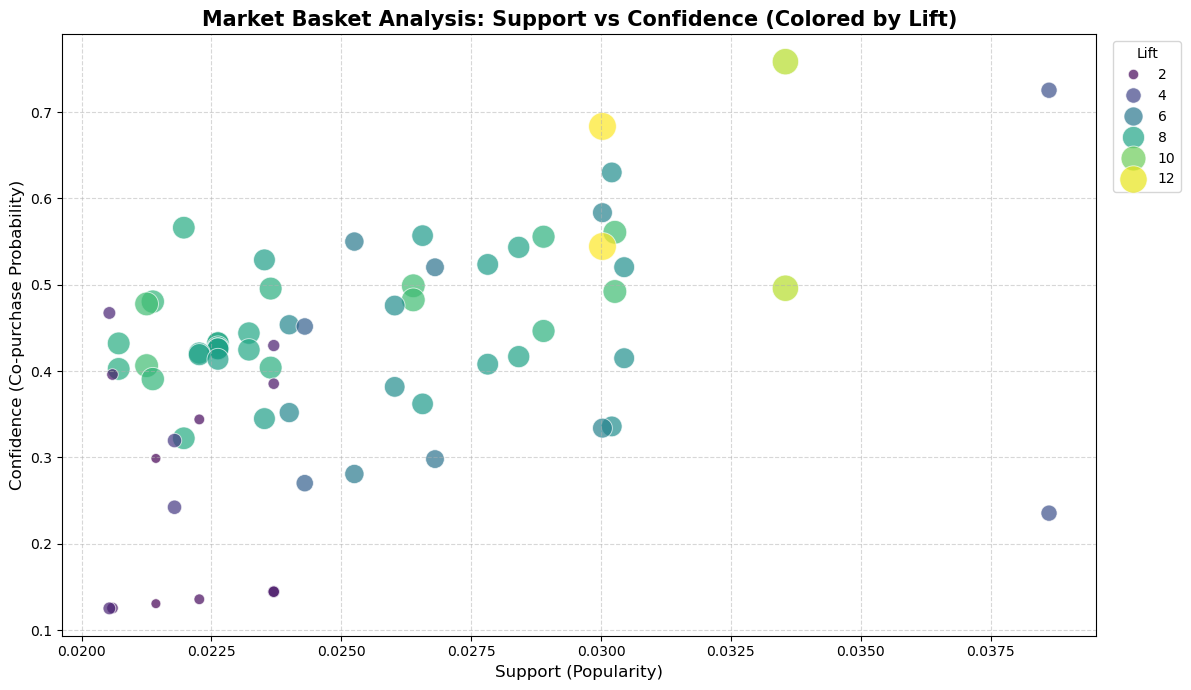

2026-03-01 01:42:00,436 - INFO - Visualization completed and displayed.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

def export_and_visualize(rules_df: pd.DataFrame, output_filename: str = 'MBA_Results_TopRules.csv'):
    """
    Exports the generated association rules to a CSV file and creates a scatter plot 
    to visualize the relationship between Support, Confidence, and Lift.
    """
    if rules_df is None or rules_df.empty:
        logging.warning("No rules available to export or visualize.")
        return

    logging.info(f"Exporting {len(rules_df)} rules to '{output_filename}'...")
    try:
        rules_df.to_csv(output_filename, index=False)
        logging.info("Export successful!")
    except Exception as e:
        logging.error(f"Failed to export rules to CSV: {e}")


    logging.info("Generating scatter plot for the Association Rules...")
    try:
        plt.figure(figsize=(12, 7))
        sns.scatterplot(
            data=rules_df, 
            x="support", 
            y="confidence", 
            hue="lift",      
            size="lift",     
            sizes=(50, 400), 
            palette="viridis",
            alpha=0.7
        )

        plt.title("Market Basket Analysis: Support vs Confidence (Colored by Lift)", fontsize=15, fontweight='bold')
        plt.xlabel("Support (Popularity)", fontsize=12)
        plt.ylabel("Confidence (Co-purchase Probability)", fontsize=12)
        plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title="Lift")
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout() 
        
        plt.show()
        logging.info("Visualization completed and displayed.")
    except Exception as e:
        logging.error(f"Failed to generate plot: {e}")

export_and_visualize(top_rules)